# 07 - Estudio de ablación

Mide el aporte de cada decisión de diseño **cambiando una sola a la vez** respecto de la configuración base
(la del informe de avance). El cómputo está en `scripts/run_ablation.py` (y las variantes de features en
`scripts/compute_features.py --variante todas`); este notebook solo lee `results/07_ablacion/` y resume.

- **CNN** (CV 5×1): augmentation, peso de la clase positiva (`balanced` ≈ 136, `sqrt` ≈ 12, `none`), tasa de
  aprendizaje decreciente (coseno) y preprocesamiento (sin detrending, sin recorte, ventana 301).
- **Random Forest / XGBoost** (18 features, CV 5×5): ponderación de clases, preprocesamiento de las curvas antes
  de extraer features y sensibilidad del BLS a la cadencia supuesta (15/30/60 min) y al rango de períodos.

Todas las configuraciones usan **la misma partición** (seed 0; la CV 5×1 es la primera repetición de la 5×5), así
que se comparan **fold a fold** contra la base: la diferencia pareada cancela la dificultad propia de cada fold,
que en el informe de avance (desviación ~0,2 entre folds) tapaba casi todas las diferencias.

In [1]:
import sys
sys.path.append('..')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.evaluation import choose_threshold, compute_metrics, paired_diff, summarize_cv

pd.set_option('display.width', 200)
DIR = Path('../results/07_ablacion')
y = pd.read_csv('../results/features_train.csv').label.to_numpy()

# Nombre legible de cada configuración (orden de las tablas y del gráfico)
ETIQUETAS = {
    'base': 'base',
    'aug': '+ augmentation',
    'peso_sqrt': 'peso positivo √(neg/pos)',
    'peso_none': 'sin peso de clase',
    'sin_peso': 'sin peso de clase',
    'cosine': '+ tasa decreciente (coseno)',
    'sin_detrend': 'sin detrending',
    'sin_recorte': 'sin recorte de picos',
    'ventana_301': 'ventana de mediana 301',
    'cadencia_15': 'cadencia supuesta 15 min',
    'cadencia_60': 'cadencia supuesta 60 min',
    'periodos_15': 'períodos BLS 0,5-15 d',
}
GRUPOS = {'cnn': 'CNN 1D', 'rf': 'Random Forest', 'xgb': 'XGBoost'}


def cargar():
    filas = []
    for grupo in GRUPOS:
        base_path = DIR / f'{grupo}_base.csv'
        if not base_path.exists():
            continue
        base = pd.read_csv(base_path)
        for variante, etiqueta in ETIQUETAS.items():
            path = DIR / f'{grupo}_{variante}.csv'
            if not path.exists():
                continue
            folds = pd.read_csv(path)
            oof = np.load(DIR / f'{grupo}_{variante}_oof.npy')
            s = summarize_cv(folds)
            d = paired_diff(folds, base)
            thr = choose_threshold(y, oof)
            m_thr = compute_metrics(np.tile(y, len(oof)), oof.ravel(), thr)
            filas.append({
                'grupo': GRUPOS[grupo], 'config': etiqueta, 'k': len(folds),
                'pr_auc': s.loc['pr_auc', 'mean'], 'pr_auc_std': s.loc['pr_auc', 'std'],
                'delta': d.mean(), 'delta_std': d.std(), 'mejora_en': f'{(d > 0).sum()}/{len(d)}',
                'recall@0.5': s.loc['recall', 'mean'], 'prec@0.5': s.loc['precision', 'mean'],
                'umbral_cv': thr, 'recall@umbral': m_thr['recall'], 'prec@umbral': m_thr['precision'],
                'deltas': d.to_numpy(),
            })
    return pd.DataFrame(filas)


abl = cargar()
print(abl.groupby('grupo').size())

grupo
Random Forest    8
XGBoost          8
dtype: int64


## Tabla resumen

- `pr_auc`: media ± desviación entre folds.
- `delta`: diferencia pareada de PR-AUC contra la base del mismo modelo (media y desviación de las diferencias por
  fold); `mejora_en`: en cuántos folds la variante supera a la base.
- `umbral_cv`: umbral que maximiza F1 sobre las predicciones fuera de fold (`choose_threshold`), con el recall y la
  precisión que da. Ojo: está elegido y medido sobre las mismas predicciones, así que es algo optimista; sirve para
  comparar configuraciones y como umbral para el test, no como estimación final.

In [2]:
fmt = abl.drop(columns='deltas').copy()
fmt['pr_auc'] = [f'{m:.3f} ± {s:.3f}' for m, s in zip(abl.pr_auc, abl.pr_auc_std)]
fmt['delta'] = [f'{m:+.3f} ± {s:.3f}' if c != 'base' else '' for m, s, c in zip(abl.delta, abl.delta_std, abl.config)]
fmt.loc[fmt.config == 'base', 'mejora_en'] = ''
fmt = fmt.drop(columns=['pr_auc_std', 'delta_std']).round(3)
fmt.to_csv('../results/07_ablacion_resumen.csv', index=False)
fmt

,grupo,config,k,pr_auc,delta,mejora_en,recall@0.5,prec@0.5,umbral_cv,recall@umbral,prec@umbral
0,Random Forest,base,25,0.394 ± 0.200,,,0.091,0.560,0.248,0.324,0.706
1,Random Forest,sin peso de clase,25,0.352 ± 0.159,-0.042 ± 0.105,10/25,0.038,0.240,0.149,0.314,0.537
2,Random Forest,sin detrending,25,0.167 ± 0.102,-0.227 ± 0.194,3/25,0.016,0.120,0.251,0.146,0.360
3,Random Forest,sin recorte de picos,25,0.306 ± 0.175,-0.088 ± 0.102,2/25,0.028,0.160,0.192,0.286,0.465
4,Random Forest,ventana de mediana 301,25,0.209 ± 0.117,-0.186 ± 0.156,3/25,0.026,0.200,0.225,0.184,0.400
5,Random Forest,cadencia supuesta 15 min,25,0.320 ± 0.158,-0.075 ± 0.142,8/25,0.049,0.360,0.212,0.254,0.540
6,Random Forest,cadencia supuesta 60 min,25,0.434 ± 0.185,+0.040 ± 0.091,16/25,0.094,0.560,0.241,0.368,0.576
7,Random Forest,"períodos BLS 0,5-15 d",25,0.411 ± 0.176,+0.017 ± 0.080,16/25,0.087,0.520,0.199,0.389,0.500
8,XGBoost,base,25,0.377 ± 0.186,,,0.335,0.417,0.669,0.324,0.566
9,XGBoost,sin peso de clase,25,0.406 ± 0.174,+0.029 ± 0.081,15/25,0.173,0.720,0.204,0.319,0.702


## Diferencia pareada contra la base

Cada punto gris es un fold; el punto azul es la media y la barra ±1 desviación de las diferencias. A la derecha de
la línea vertical, la variante supera a la base.

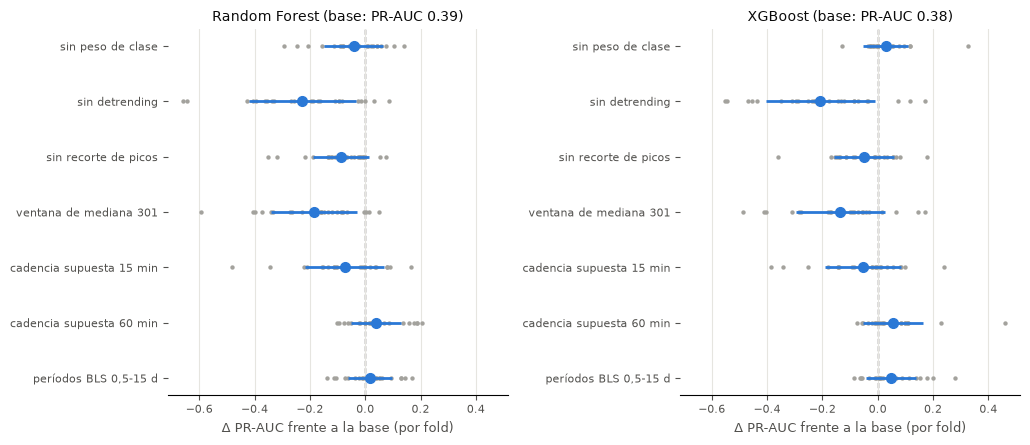

In [3]:
ACENTO, GRIS, TEXTO = '#2a78d6', '#a3a29d', '#52514e'
grupos = [g for g in GRUPOS.values() if g in set(abl.grupo)]
n_filas = abl[abl.config != 'base'].groupby('grupo').size().max()
fig, axes = plt.subplots(1, len(grupos), figsize=(5.2 * len(grupos), 0.45 * n_filas + 1.4), sharex=True, squeeze=False)
for ax, g in zip(axes[0], grupos):
    sub = abl[(abl.grupo == g) & (abl.config != 'base')].reset_index(drop=True)
    yy = np.arange(len(sub))[::-1]
    for yi, (_, r) in zip(yy, sub.iterrows()):
        ax.scatter(r.deltas, np.full(len(r.deltas), yi), s=10, color=GRIS, zorder=2, linewidths=0)
        ax.errorbar(r.delta, yi, xerr=r.delta_std, fmt='o', ms=7, color=ACENTO, elinewidth=2, capsize=0, zorder=3)
    ax.axvline(0, color=TEXTO, lw=1, ls='--', zorder=1)
    ax.set_yticks(yy, sub.config, fontsize=9)
    base_pr = abl[(abl.grupo == g) & (abl.config == 'base')].pr_auc.iloc[0]
    ax.set_title(f'{g} (base: PR-AUC {base_pr:.2f})', fontsize=10, color='#0b0b0b')
    ax.set_xlabel('Δ PR-AUC frente a la base (por fold)', fontsize=9, color=TEXTO)
    ax.grid(axis='x', color='#e6e5e0', lw=0.8)
    ax.tick_params(colors=TEXTO, labelsize=8)
    for s in ['top', 'right', 'left']:
        ax.spines[s].set_visible(False)
plt.tight_layout()
plt.savefig('../results/07_ablacion.png', dpi=150, bbox_inches='tight')
plt.show()

## Conclusiones

### Modelos clásicos (18 features, CV 5×5)

- **El preprocesamiento es la decisión que más pesa.** Sin detrending el PR-AUC cae de ~0,39 a ~0,17 (solo mejora
  en 3/25 folds, en ambos modelos): sin quitar la tendencia lenta, el BLS encuentra la variabilidad de la estrella en
  vez de los tránsitos. Con ventana 301 cae a 0,21-0,24: queda tendencia sin quitar, como se veía en las figuras
  del notebook 02. El recorte de picos aporta menos (-0,05 a -0,09 al quitarlo) pero es consistente en el RF
  (solo mejora en 2/25 folds).
- **La ponderación de clases casi no importa en los árboles** (-0,04 en RF, +0,03 en XGBoost, ambos dentro de la
  variación entre folds). Su efecto es mucho menor que el del preprocesamiento.
- **Sensibilidad al supuesto de cadencia:** el resultado varía entre 0,32 y 0,43 según la cadencia supuesta, así
  que el supuesto sí importa. El patrón es coherente: como la grilla de períodos está en días, la cadencia cambia
  cuántos puntos abarca el período máximo. Con 15 min llega a ~2.880 puntos (casi toda la curva) y el BLS puede
  ajustar una sola caída aislada como "tránsito" (lo que vimos en la estrella 28): empeora. Con 60 min, o
  limitando los períodos a 0,5-15 días con la cadencia de 30 min, el máximo baja a 720 puntos (al menos ~4
  repeticiones) y mejora levemente (+0,02 a +0,05, en 16-18/25 folds). La variante de períodos deja igual las
  duraciones y aísla el efecto: **exigir repetición del tránsito ayuda**.
- Estas mejoras se eligieron mirando la misma CV, son pequeñas frente al ruido y no se usaron para cambiar la
  configuración principal; se reportan como análisis de sensibilidad.
- Con el umbral elegido en CV (en vez de 0,5) el RF pasa de recall 0,09 a 0,32 con precisión 0,71: el umbral 0,5 es
  inadecuado con este desbalance.

### CNN 1D (CV 5×1)

*(Se completa con la corrida de `run_ablation.py --grupo cnn` en el PC de la casa.)*